# Electron energy spectrum with errors and one-count levels (FPI and FEEPS)

author: Louis Richard\
Builds the omnidirectional electron energy spectrum from 10 eV to 500 keV by combining FPI DES (burst, below 30 keV) and FEEPS (survey, above 30 keV) over a 9 s window, with its counting-statistics errors and one-count levels, as in Fig. 3 (spectrum 2) of Oka et al. (2022), Phys. Plasmas 29, 052904, without the model fits.

* FPI: the counts of each bin are $N = (f / \delta f)^2$ (`mms.vdf_counts`), the omnidirectional spectrum is the mean over the angle bins, and its error the error of that mean. The burst skymaps are used: the fast-survey skymaps are lossy compressed and their counts do not go below about 2 per bin and sample, which raises the fast spectrum where the true counts are lower.
* FEEPS: the L2 files have no counts, but their `percent_error` is $100 / \sqrt{N}$: `mms.get_feeps_alleyes` derives the counts (`"counts"`) and the intensity errors (`"fluxerr"`), and `mms.feeps_omni` sums the counts and propagates the errors of the eyes.
* One-count level: the phase-space density of one count, per bin (or eye) and sample, as the "detection limit" of Oka et al. (2022), and of one count in the whole average.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from pyrfu import mms, pyrf
from pyrfu.plot import use_pyrfu_style

use_pyrfu_style(usetex=False)
mms.db_init(default="aws")

[18-Nov-26 09:33:16] INFO: Updating MMS data access configuration in /Users/louisrichard/Library/Application Support/pyrfu/mms_config.json...


## Define time interval and spacecraft index

The spectrum is averaged over the 9 s window (300 FPI burst, two FPI fast and four FEEPS survey samples). Longer intervals are loaded to fill the one-count level of the channels without any count in the window.

In [2]:
tint_spec = ["2017-07-11T22:36:36.8383", "2017-07-11T22:36:45.8385"]
tint_long = ["2017-07-11T22:30:00", "2017-07-11T22:45:00"]
tint_brst = ["2017-07-11T22:36:20", "2017-07-11T22:37:00"]
mms_id = 3

In [3]:
def window_average(spec, spec_err, counts, tint):
    """Mean of the spectrum over the window, error of the mean (errors in
    quadrature) and counts summed."""
    spec, spec_err, counts = (pyrf.time_clip(x, tint) for x in (spec, spec_err, counts))
    n_t = len(spec.time)
    spec_avg = spec.mean("time")
    err_avg = np.sqrt((spec_err**2).sum("time")) / n_t
    return spec_avg, err_avg, counts.sum("time"), n_t


def one_count_of_average(spec_avg, counts_sum):
    """One-count level of the averaged spectrum (one count in the window)."""
    time = np.array(["2000-01-01"], dtype="datetime64[ns]")
    level = mms.vdf_one_count(
        spec_avg.expand_dims(time=time), counts_sum.expand_dims(time=time)
    )
    return level[0]

## FPI DES

### Lossy fast survey and lossless burst

The fast-survey skymaps are lossy compressed (the `compressionloss` variable of the files is 1), the burst skymaps losslessly (0). After decompression, the fast counts do not go below about 2 per bin and sample: at 27.5 keV most bins have exactly 2 counts, whereas the sum of the 150 burst samples of a fast sample gives 0.7 counts per bin, with Poisson statistics. Where the true counts are below about 2 per bin and sample, the fast spectrum stays at about twice its one-count level. The spectrum is therefore computed from the burst skymaps, available in this window, and the fast spectrum is shown for comparison.

### Counts, omnidirectional spectrum, errors and one-count levels

The counts of each bin are $N = (f / \delta f)^2$. The omnidirectional spectrum (`mms.vdf_omni`) is the mean of the 512 angle bins weighted by their solid angles $w_i$; its error is $\sqrt{\sum w_i^2 \delta f_i^2} / \sum w_i$, and its counts are the sum over the bins. The squares are computed in float64: the errors of the skymaps are float32 in s$^3$ cm$^{-6}$ (about $10^{-26}$), whose squares underflow to zero in float32.

* One count per bin and sample: $f / N$ of the bins with counts (`mms.vdf_one_count` of the skymaps), averaged over the bins and the window. It is given per 4.5 s, the fast sample on which Oka et al. (2022) defined their detection limit: the level of a 30 ms burst sample divided by 150.
* One count in the average: `mms.vdf_one_count` of the averaged spectrum with the counts summed over the bins and the window.

In [4]:
def fpi_spectrum(rate, tint):
    """Omnidirectional spectrum averaged over the window, its error and
    one-count levels (per bin and 4.5 s, and in the average)."""
    vdf = mms.get_data(f"pde_fpi_{rate}_l2", tint, mms_id)
    vdf_err = mms.get_data(f"pderre_fpi_{rate}_l2", tint, mms_id)
    counts = mms.vdf_counts(vdf, vdf_err)

    # Samples per 4.5 s (1 for fast, 150 for burst)
    dt = np.median(np.diff(vdf.time.data)) / np.timedelta64(1, "s")
    per = 4.5 / dt if rate == "brst" else 1.0

    psd = mms.vdf_omni(vdf)
    n_counts = mms.vdf_omni(counts, method="sum")
    w = mms.vdf_solid_angle(vdf).data.data.astype(np.float64)
    err = np.nan_to_num(vdf_err.data.data.astype(np.float64))
    psd_err = psd.copy(
        data=np.sqrt(np.sum((w * err) ** 2, axis=(2, 3))) / np.sum(w, axis=(2, 3))
    )
    one_bins = mms.vdf_omni(mms.vdf_one_count(vdf, counts)) / per

    psd_avg, psd_err_avg, n_sum, n_t = window_average(psd, psd_err, n_counts, tint_spec)
    one = pyrf.time_clip(one_bins, tint_spec).mean("time")
    one = one.fillna(one_bins.median("time"))
    one_avg = one_count_of_average(psd_avg, n_sum)
    energy = psd.energy.data[0] if psd.energy.ndim == 2 else psd.energy.data
    print(f"FPI {rate}: {n_t} samples in the window")
    return energy / 1e3, psd_avg, psd_err_avg, one, one_avg

In [5]:
fpi = fpi_spectrum("brst", tint_brst)
fpi_fast = fpi_spectrum("fast", tint_long)

[18-Nov-26 09:33:16] INFO: Loading mms3_des_dist_brst...


[18-Nov-26 09:36:23] INFO: Loading mms3_des_disterr_brst...


FPI brst: 300 samples in the window


[18-Nov-26 09:36:24] INFO: Loading mms3_des_dist_fast...


[18-Nov-26 09:37:36] INFO: Loading mms3_des_disterr_fast...


FPI fast: 2 samples in the window


## FEEPS

### Load the intensities, counts and intensity errors of all eyes

`"counts"` are $(100 / \mathrm{percent\_error})^2$ and `"fluxerr"` the intensity times `percent_error` / 100, from the same L2 files. The same corrections are applied to the three (energy tables, flat field, bad eyes and channels, integral channel, sunlight contamination).

In [6]:
feeps = {}
for units in ["flux", "counts", "fluxerr"]:
    alle = mms.get_feeps_alleyes(f"{units}e_srvy_l2", tint_long, mms_id)
    feeps[units] = mms.feeps_corrections(alle)

[18-Nov-26 09:37:37] INFO: Loading mms3_epd_feeps_srvy_l2_electron_spinsectnum...


[18-Nov-26 09:37:37] INFO: Loading mms3_epd_feeps_srvy_l2_electron_pitch_angle...


[18-Nov-26 09:37:37] INFO: Loading mms3_epd_feeps_srvy_l2_electron_top_intensity_sensorid_3...


[18-Nov-26 09:37:37] INFO: Loading mms3_epd_feeps_srvy_l2_electron_top_intensity_sensorid_4...


[18-Nov-26 09:37:37] INFO: Loading mms3_epd_feeps_srvy_l2_electron_top_intensity_sensorid_5...


[18-Nov-26 09:37:37] INFO: Loading mms3_epd_feeps_srvy_l2_electron_top_intensity_sensorid_11...


... (86 outputs left out)

[18-Nov-26 09:39:17] INFO: Loading mms3_epd_feeps_srvy_l2_electron_bottom_quality_indicator_sensorid_4...


[18-Nov-26 09:39:17] INFO: Loading mms3_epd_feeps_srvy_l2_electron_bottom_quality_indicator_sensorid_5...


[18-Nov-26 09:39:17] INFO: Loading mms3_epd_feeps_srvy_l2_electron_bottom_quality_indicator_sensorid_11...


[18-Nov-26 09:39:17] INFO: Loading mms3_epd_feeps_srvy_l2_electron_bottom_quality_indicator_sensorid_12...


### Omnidirectional spectrum, counts and errors

`mms.feeps_omni` combines the eyes according to the units: the intensities are averaged, the counts summed and the intensity errors combined as the error of the mean.

In [7]:
j_feeps = mms.feeps_omni(feeps["flux"])
n_feeps = mms.feeps_omni(feeps["counts"])
dj_feeps = mms.feeps_omni(feeps["fluxerr"])

### One-count levels

Per eye and sample: the intensity per count of each eye (a calibration constant per eye and channel), averaged over the eyes and the window.

In [8]:
per_count = feeps["flux"].copy()
for eye in [k for k in per_count.data_vars if k[:3] in ("top", "bot")]:
    n_eye = feeps["counts"][eye]
    per_count[eye] = (feeps["flux"][eye] / n_eye).where(n_eye > 0)

one_feeps_eyes = mms.feeps_omni(per_count, method="mean")

j_feeps_avg, dj_feeps_avg, n_feeps_sum, n_t_feeps = window_average(
    j_feeps, dj_feeps, n_feeps, tint_spec
)
one_feeps = pyrf.time_clip(one_feeps_eyes, tint_spec).mean("time")
one_feeps = one_feeps.fillna(one_feeps_eyes.median("time"))
one_feeps_avg = one_count_of_average(j_feeps_avg, n_feeps_sum)
print(f"FEEPS: {n_t_feeps} samples in the window")

FEEPS: 4 samples in the window


### Convert the intensities to phase-space densities

`mms.dpf2psd` (non-relativistic $f = m J / v^2$, as FPI) gives one factor per energy, applied to the spectrum, its error and the one-count levels.

In [9]:
flux = j_feeps_avg.expand_dims(time=j_feeps.time.data[:1]).assign_coords(
    energy=j_feeps.energy.data * 1e3
)
flux.attrs.update(UNITS="1/(cm^2 s sr keV)", species="electrons")
to_psd = (mms.dpf2psd(flux) / flux).data[0] * 1e18  # s^3 m^-6 to s^3 km^-6

j_feeps_avg, dj_feeps_avg, one_feeps, one_feeps_avg = (
    to_psd * x for x in (j_feeps_avg, dj_feeps_avg, one_feeps, one_feeps_avg)
)

energy_feeps = j_feeps.energy.data

## Plot the spectrum

As in Oka et al. (2022, Appendix A), the points below 100 eV (photoelectrons) are left out, FPI is shown below 30 keV and FEEPS above, and the points whose one-count level falls within their error bar are dropped.

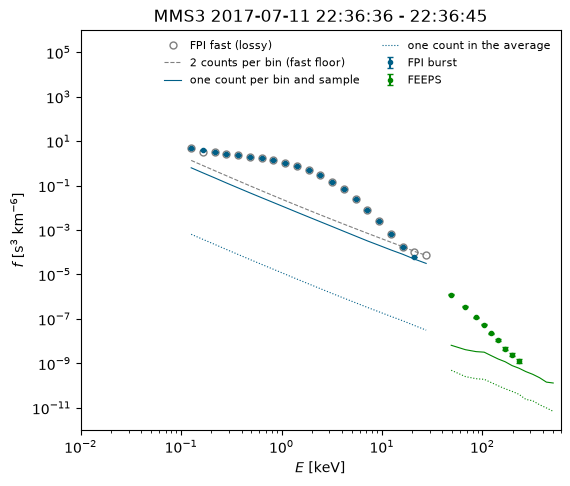

In [10]:
def in_psd(spec, factor):
    energy, psd, psd_err, one, one_avg = spec
    return (
        energy,
        factor * psd.data,
        factor * psd_err.data,
        factor * one.data,
        factor * one_avg.data,
    )


spectra = {
    "FPI burst": (*in_psd(fpi, 1e30), (0.1, 30.0)),
    "FEEPS": (
        *in_psd(
            (energy_feeps, j_feeps_avg, dj_feeps_avg, one_feeps, one_feeps_avg), 1.0
        ),
        (30.0, np.inf),
    ),
}

f, ax = plt.subplots(1, figsize=(6, 5))
f.subplots_adjust(left=0.15, right=0.95, bottom=0.12, top=0.92)

# Fast survey for comparison (lossy: floor of about 2 counts per bin and sample)
energy, psd, psd_err, one, _ = in_psd(fpi_fast, 1e30)
in_range = (energy >= 0.1) & (energy < 30.0)
keep = in_range & (psd - psd_err > one)
ax.plot(
    energy[keep],
    psd[keep],
    "o",
    ms=5,
    mfc="none",
    color="0.5",
    label="FPI fast (lossy)",
)
ax.plot(
    energy[in_range],
    2 * one[in_range],
    color="0.5",
    lw=0.8,
    ls="--",
    label="2 counts per bin (fast floor)",
)

for i, (label, (energy, psd, psd_err, one, one_avg, e_range)) in enumerate(
    spectra.items()
):
    in_range = (energy >= e_range[0]) & (energy < e_range[1])
    keep = in_range & np.isfinite(psd) & (psd - psd_err > one)
    ax.errorbar(
        energy[keep],
        psd[keep],
        yerr=psd_err[keep],
        fmt="o",
        ms=3,
        color=f"C{i}",
        capsize=2,
        label=label,
    )
    ax.plot(
        energy[in_range],
        one[in_range],
        color=f"C{i}",
        lw=0.8,
        label="one count per bin and sample" if i == 0 else None,
    )
    ax.plot(
        energy[in_range],
        one_avg[in_range],
        color=f"C{i}",
        lw=0.8,
        ls=":",
        label="one count in the average" if i == 0 else None,
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim([1e-2, 6e2])
ax.set_ylim([1e-12, 1e6])
ax.set_xlabel("$E$ [keV]")
ax.set_ylabel("$f$ [s$^3$ km$^{-6}$]")
ax.set_title(
    f"MMS{mms_id} {tint_spec[0][:10]} {tint_spec[0][11:19]} - {tint_spec[1][11:19]}"
)
ax.legend(ncol=2, handlelength=1.5, loc="upper right", frameon=False, fontsize=8)

Up to 16 keV the fast and burst spectra agree within 3 %. Above, the fast spectrum stays on the level of 2 counts per bin and 4.5 s (twice the one-count level, `mms.vdf_one_count(..., n=2)`), 1.7 times above the burst spectrum at 21 keV and 2.8 times at 27.5 keV, where the burst spectrum falls below its one-count level. The relative error of the burst spectrum is 0.3-3.3 % (300 samples of 512 bins), the largest at 21 keV. The relative error of FEEPS grows from 2 % at 49 keV to 19 % at 231 keV, the last channel above its one-count level. After the corrections only 2 to 6 of the 10 eyes have data in each sample (the others removed by the sunlight and bad-data masks), and the omnidirectional spectrum averages, and sums the counts of, these eyes only.

The level of one count in the whole average is lower than the level per bin (or eye with data) by the number of bins times the number of samples (FPI: 512 bins and 300 / 150 = 2 times 4.5 s). It is the level relevant to the averaged spectrum itself; the level per bin and sample (the "detection limit" of Oka et al., 2022) tells where each measurement is a single count.